In [24]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense , Input  , Flatten
import matplotlib.pyplot as plt
import numpy as np


In [12]:
(X_train , y_train)   , (X_test , y_test)= mnist.load_data()

In [13]:
X_train.shape

(60000, 28, 28)

In [18]:
image =X_train[0]
label = y_train[0]

Text(0.5, 1.0, 'Label 5')

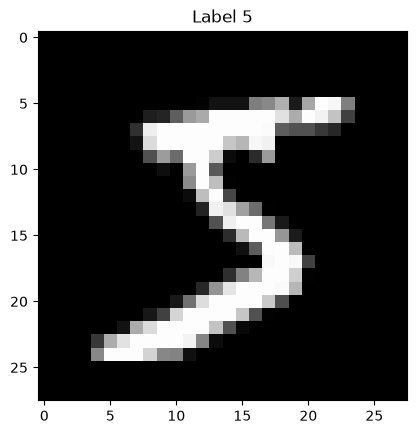

In [22]:
plt.imshow(image , cmap = "gray")
plt.title(f"Label {label}")

In [23]:
X_train_scale = X_train / 255.0
X_test_scale = X_test / 255.0

In [26]:
model = Sequential([
    Input(shape= (28,28)),
    Flatten(),
    Dense(128), 
    Dense(64),
    Dense(10, activation = "softmax")
])

In [27]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
model.compile(
    optimizer = "adam",
    loss = ["sparse_categorical_crossentropy"],
    metrics = ["accuracy"]
)

In [34]:
model.fit(X_train , y_train , epochs = 50 ,batch_size = 32, verbose = 1)

Epoch 1/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8649 - loss: 0.7891
Epoch 2/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8723 - loss: 0.6017
Epoch 3/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8748 - loss: 0.5391
Epoch 4/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8797 - loss: 0.4753
Epoch 5/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8839 - loss: 0.4392
Epoch 6/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8901 - loss: 0.4065
Epoch 7/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8916 - loss: 0.3917
Epoch 8/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8958 - loss: 0.3872
Epoch 9/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8970 - loss: 0.3741
Epoch 10/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8971 - loss: 0.3827
Epoch 11/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8982 - loss: 0.3734
Epoch 12/50
1875/1875 ━━━━━━

In [35]:
loss , accuracy = model.evaluate(X_test , y_test)
print(f"test_accuracy {accuracy}" )

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8839 - loss: 0.4553
test_accuracy 0.883899986743927


In [37]:
X_test[0].shape

(28, 28)

In [ ]:
prediction = model.predict(
    X_test[0].reshape(1,28,28)
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 366ms/step


In [43]:
prediction

array([[1.9880196e-07, 1.1664967e-12, 2.3220264e-05, 1.1459707e-03,
        3.2399672e-09, 1.0556939e-06, 1.5382058e-11, 9.9876499e-01,
        1.0083382e-06, 6.3620209e-05]], dtype=float32)

In [41]:
digit = np.argmax(prediction)
digit

7

In [42]:
y_test[0]

7

Text(0.5, 1.0, 'Actual: 7, Predicted:7')

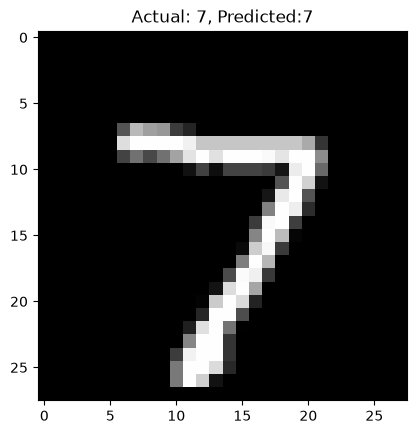

In [48]:
plt.imshow(X_test[0] , cmap= "gray")
plt.title(f"Actual: {y_test[0]}, Predicted:{digit}")

In [49]:
model.save("ann_mnist.keras")